# VIBES with the ELBO solved to convergence (3 Nov 2026)

Every step here reads saved outputs of `workflows/vibes_newton_refit_20261103.py`; nothing is refitted.
Conclusions and caveats are in `docs/vibes-newton-adoption-tests-2026-11-03.md`.

In [1]:
import json, os
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
AREA = Path(os.environ.get("AETH_AREA", "."))
T = AREA / "output/tables"; N = T / "vibes_newton_20261103"; G = T / "vibes_gpu_bench_20261103"
SAVED, NEWTON = "#2a78d6", "#eb6834"; INK = "#3a3a38"
plt.rcParams.update({"figure.dpi": 130, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#9a9a95", "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
                     "axes.grid": True, "grid.color": "#e8e8e4", "grid.linewidth": .6, "lines.linewidth": 1.2})
pd.set_option("display.width", 200, "display.max_columns", 30)

## 1. L-BFGS-B port against the saved run
Fused SciPy is the noise floor: same algorithm, last bits of the objective differ.

In [2]:
pd.read_csv(N / "port/port_vs_saved.csv").rename(columns={"s1": "sigma >1 %", "s10": "sigma >10 %", "s2x": "sigma >2x", "b5": "baselines >5 %", "b20": "baselines >20 %", "short": "stops <30 its", "short_shared": "shared with saved (155)", "same_it": "same iteration count"})

,run,n,sigma >1 %,sigma >10 %,sigma >2x,baselines >5 %,baselines >20 %,stops <30 its,shared with saved (155),same iteration count
0,fused SciPy,4447,17.6,5.6,1.08,100,23,156,154,171
1,old JAX,4447,24.9,13.3,9.83,467,277,281,15,13
2,L-BFGS-B port,4447,18.6,6.8,1.78,131,34,150,144,164


Does a tighter `ftol` alone cure the premature stops? 60 premature-stop and 60 other spectra, SciPy, maxiter 10,000.

In [3]:
d = pd.read_csv(N / "port/ftol.csv")
d.groupby(["ftol", "short"]).agg(n=("row", "size"), median_iterations=("nit", "median"), seconds_total=("s", "sum"), median_gap_to_optimum=("gap", "median"), gap_over_1=("gap", lambda v: int((v > 1).sum()))).round(3)

n  median_iterations  seconds_total  median_gap_to_optimum  gap_over_1
ftol         short                                                                         
0.000000e+00 False  60             5591.0        147.892                  0.000           9
             True   60            10000.0        218.583                  3.573          30
1.000000e-15 False  60             5391.5        219.043                  0.000           9
             True   60             8299.5        206.328                 40.978          33
1.000000e-12 False  60             3599.5        150.688                  0.000           9
             True   60             4506.0        146.810                934.557          36
2.220446e-09 False  60             1751.5        101.462                  0.095          16
             True   60               11.0          0.665               5962.635          60

## 2. Calibration rebuilt on Newton baselines
Same procedure as the frozen model. On the saved baselines it returns the frozen coefficients to 6e-15.

In [4]:
pd.read_csv(N / "calibration_scores.csv").round(4)

,method,k,selected,predictive_R2,RMSE,MAE,bias,n_train,n_test
0,saved,4,True,0.5416,3.8501,2.2612,0.2106,10066,2327
1,newton,4,True,0.5417,3.8499,2.2611,0.2117,10066,2327


## 3. Transfer scoring

In [5]:
r = pd.read_csv(N / "transfer/ratios_by_loading.csv")
w = ["IMPROVE out-of-site MAE (µg)", "Addis OLS slope vs HIPS", "Addis OLS intercept vs HIPS (µg)"]
r[r.what.isin(w) & r.model.isin(["vibes", "vibes_newton", "anchorhp_newton"])].pivot_table(index=["what", "k"], columns="model", values="median").round(3)

model                                anchorhp_newton   vibes  vibes_newton
what                             k                                        
Addis OLS intercept vs HIPS (µg) 5            -9.245  -5.581        -5.260
                                 8           -17.798 -17.858       -18.040
                                 12          -22.128 -25.938       -26.606
                                 18          -25.311 -34.409       -35.240
Addis OLS slope vs HIPS          5             0.686   0.426         0.414
                                 8             1.210   1.025         1.029
                                 12            1.413   1.391         1.410
                                 18            1.593   1.724         1.744
IMPROVE out-of-site MAE (µg)     5             1.283   1.335         1.339
                                 8             1.223   1.252         1.248
                                 12            1.169   1.145         1.141
                                 18            1.101   1.154         1.148

## 4. Functional-group band areas of the corrected spectra

In [6]:
pd.read_csv(N / "band_areas.csv").round(4)

,group,band,n,median_area,median_change,p99_change,gt5pct,gt20pct,r
0,improve,O-H / N-H 3000-3600,12393,5.2599,0.0000,0.1729,273,95,1.0000
1,improve,C-H 2800-3000,12393,1.8149,0.0001,0.2748,298,183,1.0000
2,improve,carbonyl 1650-1800,12393,1.1339,0.0000,0.0842,177,19,1.0000
3,improve,1600 band 1500-1650,12393,0.7353,0.0000,0.2248,242,141,1.0000
4,improve,fingerprint 1250-1500,12393,3.1398,0.0000,0.1093,185,73,1.0000
5,improve,Si-O 980-1100,12393,2.0268,0.0000,0.1435,275,72,1.0000
6,addis,O-H / N-H 3000-3600,233,3.5707,0.0001,0.0598,3,1,0.9985
7,addis,C-H 2800-3000,233,1.6896,0.0001,0.1688,7,2,0.9964
8,addis,carbonyl 1650-1800,233,1.0153,0.0001,0.3459,8,7,0.9529
9,addis,1600 band 1500-1650,233,1.4812,0.0001,0.2783,8,7,0.9551


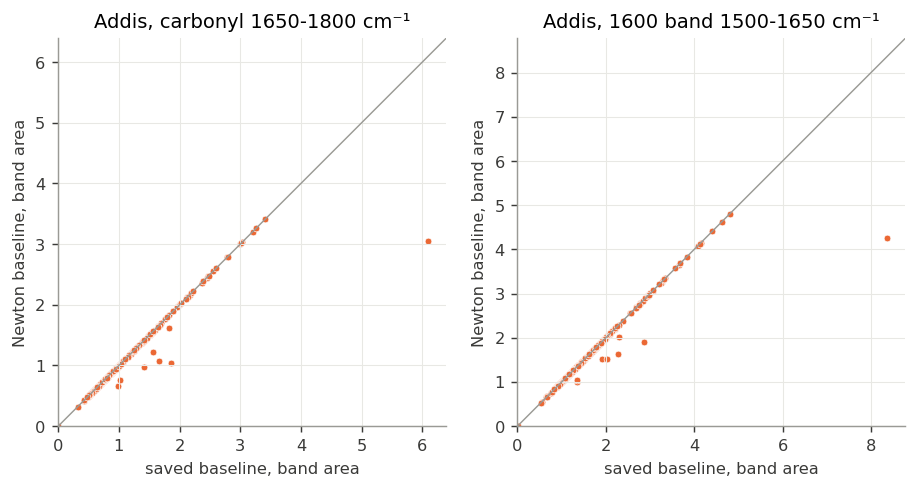

In [7]:
z = np.load(N / "band_areas_per_spectrum.npz")
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.6))
for ax, b in zip(axs, ["carbonyl 1650-1800", "1600 band 1500-1650"]):
    a = z[f"addis|{b}"]; lim = [min(a.min(), 0), a.max() * 1.05]
    ax.plot(lim, lim, color="#9a9a95", lw=.8)
    ax.scatter(a[:, 0], a[:, 1], s=14, color=NEWTON, edgecolor="white", linewidth=.4)
    ax.set(xlim=lim, ylim=lim, xlabel="saved baseline, band area", ylabel="Newton baseline, band area", title=f"Addis, {b} cm⁻¹", aspect="equal")
fig.tight_layout(); plt.show()

## 5. Lots, blanks and spikes
Same scoring code as `vibes_lot241_20261026`.

In [8]:
A = pd.read_csv(T / "vibes_lot241_20261026/blank_residue_by_lot.csv"); B = pd.read_csv(N / "lots/blank_residue_by_lot.csv")
m = A.merge(B, on=["family", "lot"], suffixes=("_saved", "_newton"))
print("failed fits, all banks: saved", int(A.failed.sum()), " Newton", int(B.failed.sum()))
m[m.family.isin(["b87", "lot241_spartan_r70", "lobo_r70"])][["family", "lot", "n_saved", "failed_saved", "failed_newton", "rms_all_saved", "rms_all_newton", "rms_ptfe_saved", "rms_ptfe_newton"]].round(6)

failed fits, all banks: saved 8  Newton 0


,family,lot,n_saved,failed_saved,failed_newton,rms_all_saved,rms_all_newton,rms_ptfe_saved,rms_ptfe_newton
0,b87,241,4,0,0,0.000329,0.000321,0.001161,0.001153
1,b87,241a,5,0,0,0.000624,0.000500,0.001673,0.001457
2,b87,248,37,0,0,0.000039,0.000033,0.000105,0.000091
3,b87,250,60,0,0,0.000034,0.000032,0.000089,0.000084
4,b87,251,333,0,0,0.000028,0.000027,0.000082,0.000082
5,b87,253,67,0,0,0.000032,0.000032,0.000095,0.000091
12,lobo_r70,241,4,0,0,0.000018,0.000018,0.000047,0.000046
13,lobo_r70,241a,5,0,0,0.000025,0.000024,0.000052,0.000051
18,lot241_spartan_r70,248,37,1,0,0.000031,0.000030,0.000092,0.000077
19,lot241_spartan_r70,250,60,3,0,0.000028,0.000027,0.000066,0.000061


In [9]:
A = pd.read_csv(T / "vibes_lot241_20261026/spike_recovery_by_lot.csv"); B = pd.read_csv(N / "lots/spike_recovery_by_lot.csv")
m = A.merge(B, on=["family", "lot", "amplitude"], suffixes=("_saved", "_newton"))
m[m.family.eq("b87")][["lot", "amplitude", "rel_rmse_saved", "rel_rmse_newton", "recovered_2920_saved", "recovered_2920_newton"]].round(4)

,lot,amplitude,rel_rmse_saved,rel_rmse_newton,recovered_2920_saved,recovered_2920_newton
0,241,0.01,0.2780,0.2813,0.8923,0.8930
1,241,0.05,0.1774,0.1781,0.9767,0.9768
2,241,0.15,0.0831,0.0833,0.9977,0.9977
3,241a,0.01,0.6081,0.4621,0.8807,0.8724
4,241a,0.05,0.2245,0.3090,0.9806,0.9806
5,241a,0.15,0.0999,0.1343,0.9982,0.9982
6,248,0.01,0.1169,0.1201,0.9349,0.9338
7,248,0.05,0.0214,0.0213,0.9901,0.9904
8,248,0.15,0.0072,0.0077,0.9987,0.9987
9,250,0.01,0.1409,0.1413,0.9205,0.9198


## 6. Continuum injection

In [10]:
pd.read_csv(N / "inject/summary.csv").round(5)

,variant,shape,saved,newton
0,"minus 1, nu, nu^2",flat,1.00000,1.00000
1,"minus 1, nu, nu^2",light-filter residual RMS,0.02921,0.02921
2,"minus 1, nu, nu^2",nu^1 (BC-like),1.00000,1.00000
3,"minus 1, nu, nu^2",nu^2 (scattering-like),1.00000,1.00000
4,minus nu^1 direction,flat,0.75653,0.75653
5,minus nu^1 direction,light-filter residual RMS,0.02889,0.02889
6,minus nu^1 direction,nu^1 (BC-like),1.00000,1.00000
7,minus nu^1 direction,nu^2 (scattering-like),1.01600,1.01600
8,production (rank 70),flat,0.00330,0.00326
9,production (rank 70),light-filter residual RMS,0.00180,0.00180


## 7. Blank banks
Same scoring as `run_oct1_remaining_20261007`; the capped 87-blank arrays stay the saved ones.

In [11]:
from IPython.display import display
for f in sorted((N / "banks").glob("*.csv"))[:8]:
    print(f.name)
    display(pd.read_csv(f).head(8).round(4))

blank_analog_overlap.csv


,group,a,b,shared,n,jaccard
0,All Addis,AIRSpec,VIBES-full-r70,64,500,0.0684
1,All Addis,AIRSpec,VIBES-lot251,61,500,0.0650
2,All Addis,AIRSpec,VIBES-allblanks,54,500,0.0571
3,All Addis,AIRSpec,VIBES-lot251-x1,58,500,0.0616
4,All Addis,AIRSpec,VIBES-allblanks-x1,59,500,0.0627
5,All Addis,VIBES-full-r70,VIBES-lot251,287,500,0.4025
6,All Addis,VIBES-full-r70,VIBES-allblanks,279,500,0.3870
7,All Addis,VIBES-full-r70,VIBES-lot251-x1,382,500,0.6181


blank_banks.csv


,baseline,label,policy,run,n_blanks,n_improve,n_etad,n_lot251,n_lot248,n_test_site,rank,rank_cap,n_failed,n_failed_improve,hours
0,VIBES-full-r70,"VIBES, capped bank (87 blanks, rank 70)",capped,full500-rank85-9345e818c61929fe,87,59,28,67,13,0,70,85,2,0,6.00
1,VIBES-lot251,"VIBES, every labeled lot-251 blank",lot251_all,full500-rank85-lot251_all-e8c225cfe1039373,288,271,17,288,0,0,13,85,0,0,0.99
2,VIBES-allblanks,"VIBES, every labeled blank (lots 248 + 251)",all_labeled,full500-rank85-all_labeled-6c6f83d021a39d39,366,338,28,340,19,55,15,85,0,0,1.36
3,VIBES-lot251-x1,"VIBES, lot-251 blanks minus the LABE1 outlier",lot251_all_minus_LABE1,full500-rank85-lot251_all-x1-6f1131126d776e45,287,270,17,287,0,0,78,85,9,1,6.34
4,VIBES-allblanks-x1,"VIBES, every labeled blank minus the LABE1 out...",all_labeled_minus_LABE1,full500-rank85-all_labeled-x1-5cc21fbaaccbb1f7,365,337,28,339,19,55,80,85,17,0,7.64


blank_fit_ladder.csv


,model_id,family,baseline,mask,group,population,stage,k,n,R2,RMSE,bias,deming_slope,deming_intercept,ols_slope,...,nrmse,deming_lambda,eval_group,t2_beyond_p95,q_beyond_p95,t2_median_ratio,q_median_ratio,improve_test_t2_beyond_p95,improve_test_q_beyond_p95,loading_beyond_train_p95,loading_beyond_train_max,addis_loading_median_ug,train_loading_median_ug,train_loading_p95_ug,intercept_rel
0,standard|AIRSpec,standard,AIRSpec,NaN,standard,own,calibration fit,8,9030,0.6736,0.1789,-0.0001,0.6799,0.0579,0.6797,...,0.9875,620.0130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4976
1,standard|AIRSpec,standard,AIRSpec,NaN,standard,own,cross-validation,8,9030,0.6222,0.1926,-0.0013,0.6443,0.0632,0.6440,...,1.0634,620.0130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.5432
2,standard|AIRSpec,standard,AIRSpec,NaN,standard,own,IMPROVE test sites,8,2078,0.7319,0.0999,0.0065,0.9330,0.0174,0.9325,...,0.6178,649.5018,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.1529
3,standard|AIRSpec,standard,AIRSpec,NaN,standard,addis,Addis test set,8,233,0.6703,3.2352,-3.1753,0.5635,-1.0766,NaN,...,NaN,NaN,All Addis,0.0043,0.0086,0.1780,0.2170,0.038,0.0366,1.0,0.0,33.7737,3.8095,16.5246,-0.2298
4,standard|AIRSpec,standard,AIRSpec,NaN,standard,addis,Addis test set,8,102,0.4352,3.1554,-3.0924,0.2819,-0.0125,NaN,...,NaN,NaN,Dry (Oct-Feb),0.0098,0.0196,0.1065,0.1685,0.038,0.0366,1.0,0.0,30.7700,3.8095,16.5246,-0.0029
5,standard|AIRSpec,standard,AIRSpec,NaN,standard,addis,Addis test set,8,60,0.7771,3.2684,-3.2207,0.4822,-0.7645,NaN,...,NaN,NaN,Belg (Mar-May),0.0000,0.0000,0.1923,0.2088,0.038,0.0366,1.0,0.0,34.0161,3.8095,16.5246,-0.1634
6,standard|AIRSpec,standard,AIRSpec,NaN,standard,addis,Addis test set,8,71,0.5168,3.3193,-3.2559,0.5072,-0.4924,NaN,...,NaN,NaN,Kiremt (Jun-Sep),0.0000,0.0000,0.3948,0.3233,0.038,0.0366,1.0,0.0,40.1306,3.8095,16.5246,-0.0878
7,analog|AIRSpec|oct1|All Addis,analog,AIRSpec,oct1,All Addis,own,calibration fit,20,392,0.8987,0.0655,0.0000,0.9002,0.0237,0.8988,...,0.2765,58.3310,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.1266


... (6 outputs left out)

blank_vip_bands.csv


,model_id,band,low,high,n_channels,vip2_share,vip_mean,vip_ge1_fraction
0,standard|AIRSpec,O–H stretch,3200,3600,312,0.2494,1.2217,0.7115
1,standard|AIRSpec,aliphatic C–H,2800,3000,156,0.2293,1.6471,1.0000
2,standard|AIRSpec,2500–2800 shoulder,2500,2800,233,0.0732,0.7746,0.1459
3,standard|AIRSpec,aromatic C–H / N–H,3000,3200,155,0.1646,1.4567,1.0000
4,standard|AIRSpec,above 3600 (baseline),3600,4000,310,0.0123,0.1497,0.0000
5,standard|AIRSpec,carbonyl,1650,1800,117,0.2079,1.7686,0.8462
6,standard|AIRSpec,aromatic C=C / 1600 band,1500,1650,117,0.0536,0.8574,0.4103
7,standard|AIRSpec,1425–1500,1425,1500,58,0.0000,0.0064,0.0000


standard_saved_vs_newton.csv


,baseline,stage,run,k,n,R2,RMSE,slope,intercept
0,AIRSpec,Addis test set,saved,8,233,0.6703,3.2352,0.5635,-1.0766
1,AIRSpec,Addis test set,newton,8,233,0.6703,3.2352,0.5635,-1.0766
2,AIRSpec,IMPROVE test sites,saved,8,2078,0.7319,0.0999,0.9330,0.0174
3,AIRSpec,IMPROVE test sites,newton,8,2078,0.7319,0.0999,0.9330,0.0174
4,VIBES-full-r70,Addis test set,saved,11,233,0.7086,2.0505,1.5269,-4.3533
5,VIBES-full-r70,Addis test set,newton,11,233,0.7086,2.0505,1.5269,-4.3533
6,VIBES-full-r70,IMPROVE test sites,saved,11,2078,0.7425,0.0985,0.9464,0.0167
7,VIBES-full-r70,IMPROVE test sites,newton,11,2078,0.7425,0.0985,0.9464,0.0167


## 8. The Addis premature-stop scans
Residual from the Addis EC-HIPS line fitted on filters whose baseline did not change (µg/m³).

In [12]:
r = pd.read_csv(N / "within_site_residuals.csv")
print("all changed filters, closer to their site line:", r.closer.value_counts().to_dict())
chk = pd.read_csv(N / "addis_premature_checks.csv")  # every Addis PM2.5 early stop, not only the largest movers
a = r[r["filter"].isin(chk.filter_key)].sort_values("dEC")
print("the %d Addis early stops:" % len(a), a.closer.value_counts().to_dict(), "| mean residual saved %.3f, Newton %.3f; mean |residual| saved %.3f, Newton %.3f" % (a.res_saved.mean(), a.res_newton.mean(), a.res_saved.abs().mean(), a.res_newton.abs().mean()))
a[["filter", "it", "es", "en", "h", "res_saved", "res_newton"]].round(3)

all changed filters, closer to their site line: {'newton': 40, 'saved': 35}
the 10 Addis early stops: {'newton': 6, 'saved': 4} | mean residual saved 0.096, Newton -0.062; mean |residual| saved 0.202, Newton 0.148


,filter,it,es,en,h,res_saved,res_newton
25,ETAD-0053,13,1.446,1.113,4.72,0.279,-0.054
31,ETAD-0166,15,1.634,1.344,5.44,0.165,-0.125
33,ETAD-0205,12,1.399,1.162,4.77,0.211,-0.026
32,ETAD-0194,22,1.245,1.078,4.41,0.207,0.041
30,ETAD-0162,12,1.185,1.068,4.49,0.114,-0.003
22,ETAD-0004,12,0.926,0.813,4.08,0.027,-0.086
26,ETAD-0056,13,1.406,1.306,4.13,0.486,0.386
29,ETAD-0150,7,0.928,0.828,4.72,-0.240,-0.339
23,ETAD-0008,14,0.719,0.654,4.17,-0.218,-0.283
28,ETAD-0141,18,1.061,0.996,4.64,-0.073,-0.137


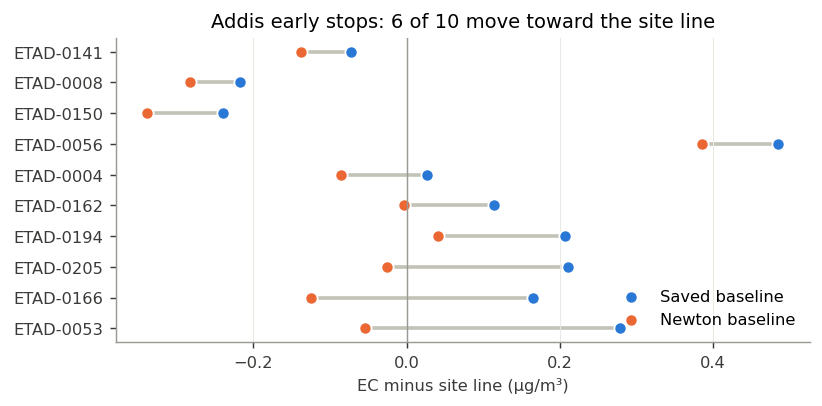

In [13]:
fig, ax = plt.subplots(figsize=(6.4, 3.2))
y = np.arange(len(a))
ax.hlines(y, a.res_saved, a.res_newton, color="#c3c2b7", lw=2, zorder=1)
ax.scatter(a.res_saved, y, s=46, color=SAVED, edgecolor="white", linewidth=1, zorder=2, label="Saved baseline")
ax.scatter(a.res_newton, y, s=46, color=NEWTON, edgecolor="white", linewidth=1, zorder=2, label="Newton baseline")
ax.axvline(0, color="#9a9a95", lw=.8); ax.set_yticks(y, a["filter"]); ax.grid(axis="y", visible=False)
ax.set(xlabel="EC minus site line (µg/m³)", title="Addis early stops: 6 of 10 move toward the site line"); ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); plt.show()

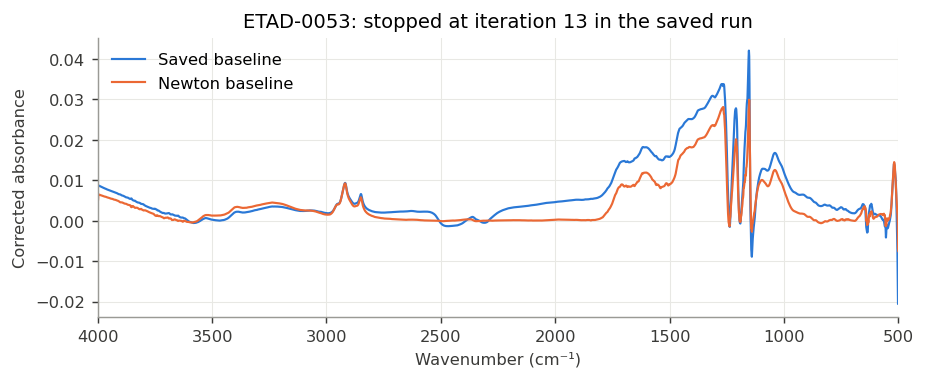

In [14]:
sv = np.load(G / "bundle_v2/saved_baselines.npy", mmap_mode="r"); nw = np.load(T / "network_baselines_v2_20261103/vibes_baselines_model_grid.npy", mmap_mode="r")
X = np.load(G / "bundle_v2/X_model_grid.npy", mmap_mode="r"); wn = np.load(G / "bundle_v2/background_model.npz")["wn"]
fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.plot(wn, np.asarray(X[1043]) - np.asarray(sv[1043]), color=SAVED, label="Saved baseline")
ax.plot(wn, np.asarray(X[1043]) - np.asarray(nw[1043]), color=NEWTON, label="Newton baseline")
ax.set(xlim=(4000, 500), xlabel="Wavenumber (cm⁻¹)", ylabel="Corrected absorbance", title="ETAD-0053: stopped at iteration 13 in the saved run"); ax.legend(frameon=False)
fig.tight_layout(); plt.show()

## 9. The v2 run

In [15]:
print(json.dumps(json.loads((T / "network_baselines_v2_20261103/MANIFEST.json").read_text()), indent=1))
d = pd.read_csv(T / "network_baselines_v2_20261103/vibes_fit_diagnostics.csv")
d.groupby("filter_type").agg(analyses=("case_row", "size"), premature=("premature_stop", "sum"), moved_gt5pct=("baseline_change_frac_rms", lambda v: int((v > .05).sum())), moved_gt20pct=("baseline_change_frac_rms", lambda v: int((v > .2).sum())))

{
 "created": "2026-11-04T01:37:12Z",
 "supersedes": null,
 "sits_next_to": "network_baselines_20261019 (unchanged)",
 "method": "same objective, background, tau and inputs; ELBO solved to convergence by vibes_batch.fit_elbo_newton",
 "vibes_batch_sha256": "740637cdc7bafd27feb289d4322899452f110ba9ac9433bdd3bc8b30e319b584",
 "analyses": 4452,
 "elbo_success": 4452,
 "map_certified": 4452,
 "premature_stop_flagged": 155,
 "pls_model": "research/ftir_hips_chem/output/tables/vibes_newton_20261103/pls_full_pool_newton_k4.npz",
 "lot241_overrides": 76
}


,analyses,premature,moved_gt5pct,moved_gt20pct
filter_type,,,,
FB,545,42,144,65
PM10,222,14,24,14
PM2.5,3685,99,174,100
